#                             **# Severe Workplace Injury Incidents in Texas Logistics (2015–2025)**

# # Data Source and Preparation:
The original data was exported from OSHA’s Severe Injury Reports. It includes severe injury reports from across the United States. For this project, I filtered the data to Texas logistics records using NAICS codes 484, 492, and 493, resulting in 517 records.

OSHA’s FinalNarrative field describes each incident. I used AI functions in Google Sheets to create two additional fields, types_of_accidents and reason, based on those narratives. These are AI-assisted classifications I added for this analysis; they are not OSHA-provided categories. Narratives may lack enough detail to classify an incident confidently.

In the initial AI-assisted classification, many narratives were labeled “Insufficient detail.” I revised the criteria for assigning reason categories and reclassified the narratives. The reason categories are interpretations based on the narrative, not confirmed causes or official OSHA classifications.

Before analysis, I removed accidental unnamed columns, standardized data types, trimmed extra spaces, and created Inspection_Recorded to indicate whether an inspection number was present.



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pathlib as path
import seaborn as sns
df = pd.read_csv('logistics_cleaned_update.csv')

1. Which accident types are most common?

Types_of_accidents
Contact with objects and equipment                   191
Falls, slips, trips                                  150
Transportation incidents                              90
Exposure to harmful substances or environments        62
Overexertion and bodily reaction                      11
Violence and other injuries by persons or animals      7
Fires and explosions                                   6
Name: count, dtype: int64


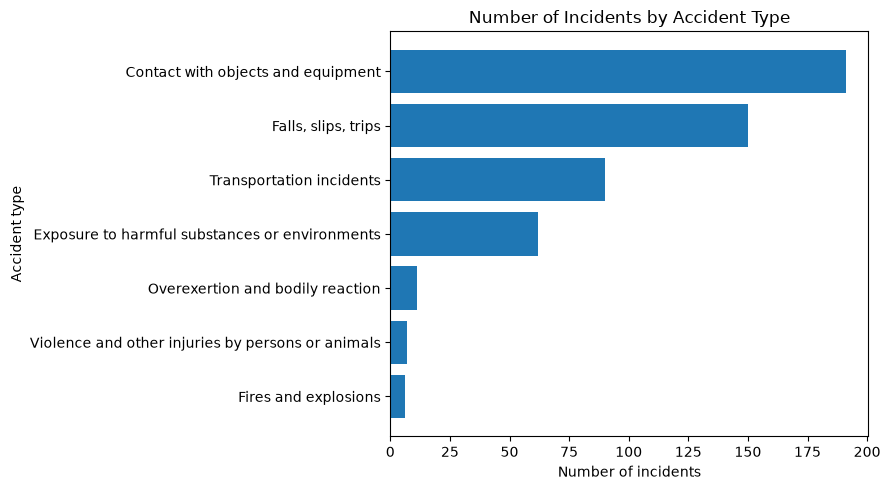

In [14]:
type_of_Injury = df['Types_of_accidents'].value_counts()

sorted_counts = type_of_Injury.sort_values()
print(sorted_counts.sort_values(ascending=False))

plt.figure(figsize=(9, 5))
plt.barh(sorted_counts.index, sorted_counts.values)

plt.title("Number of Incidents by Accident Type")
plt.xlabel("Number of incidents")
plt.ylabel("Accident type")
plt.tight_layout()
plt.show()

# Interpretation:
Contact with objects and equipment was the most frequently reported accident type, with 191 incidents. Falls, slips, and trips were next, with 150 incidents. Fires and explosions were least common, with 6 incidents.


2. Which reasons were assigned most often?

Reason
Powered Equipment & Vehicle Operation    132
Pinch Point & Machine Entanglement       105
Mounting, Dismounting & Elevated Work     99
Environmental Exposure                    52
Walking Surface Slip / Trip               50
Struck by Falling or Shifting Freight     38
Manual Material Handling & Ergonomics     24
Chemical Exposure                         17
Name: count, dtype: int64


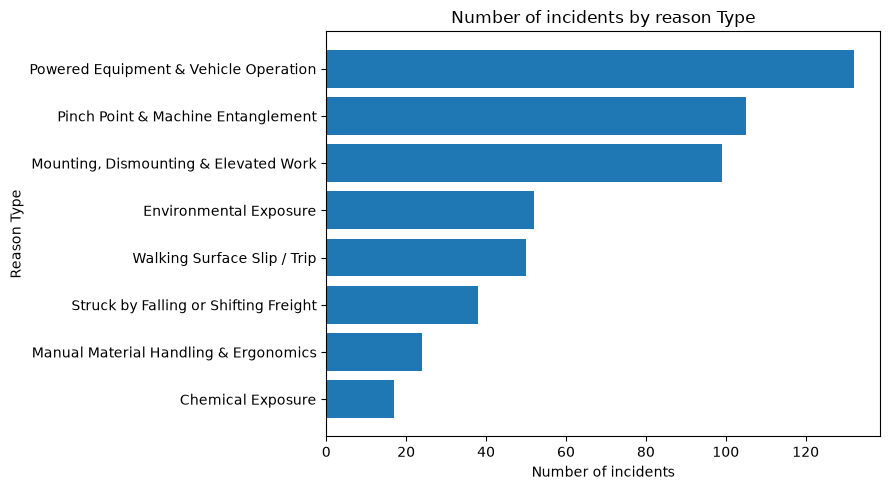

In [ ]:

type_of_reason = df['Reason'].value_counts()
print(type_of_reason.sort_values(ascending=False))

import matplotlib.pyplot as plt

sorted_counts = type_of_reason.sort_values()

plt.figure(figsize=(9, 5))
plt.barh(sorted_counts.index, sorted_counts.values)

plt.title("Number of incidents by reason Type")
plt.xlabel("Number of incidents")
plt.ylabel("Reason Type")
plt.tight_layout()
plt.show()


Interpretation
Powered Equipment & Vehicle Operation was the most frequently assigned reason category, with 132 incidents. Pinch Point & Machine Entanglement ranked second, with 105 incidents. Chemical Exposure was the least common category, with 17 incidents.

3. How do the assigned reasons differ across accident types?

Reason                                             Chemical Exposure  \
Types_of_accidents                                                     
Contact with objects and equipment                                 0   
Exposure to harmful substances or environments                    14   
Falls, slips, trips                                                0   
Fires and explosions                                               3   
Overexertion and bodily reaction                                   0   
Transportation incidents                                           0   
Violence and other injuries by persons or animals                  0   

Reason                                             Environmental Exposure  \
Types_of_accidents                                                          
Contact with objects and equipment                                      1   
Exposure to harmful substances or environments                         43   
Falls, slips, trips                        

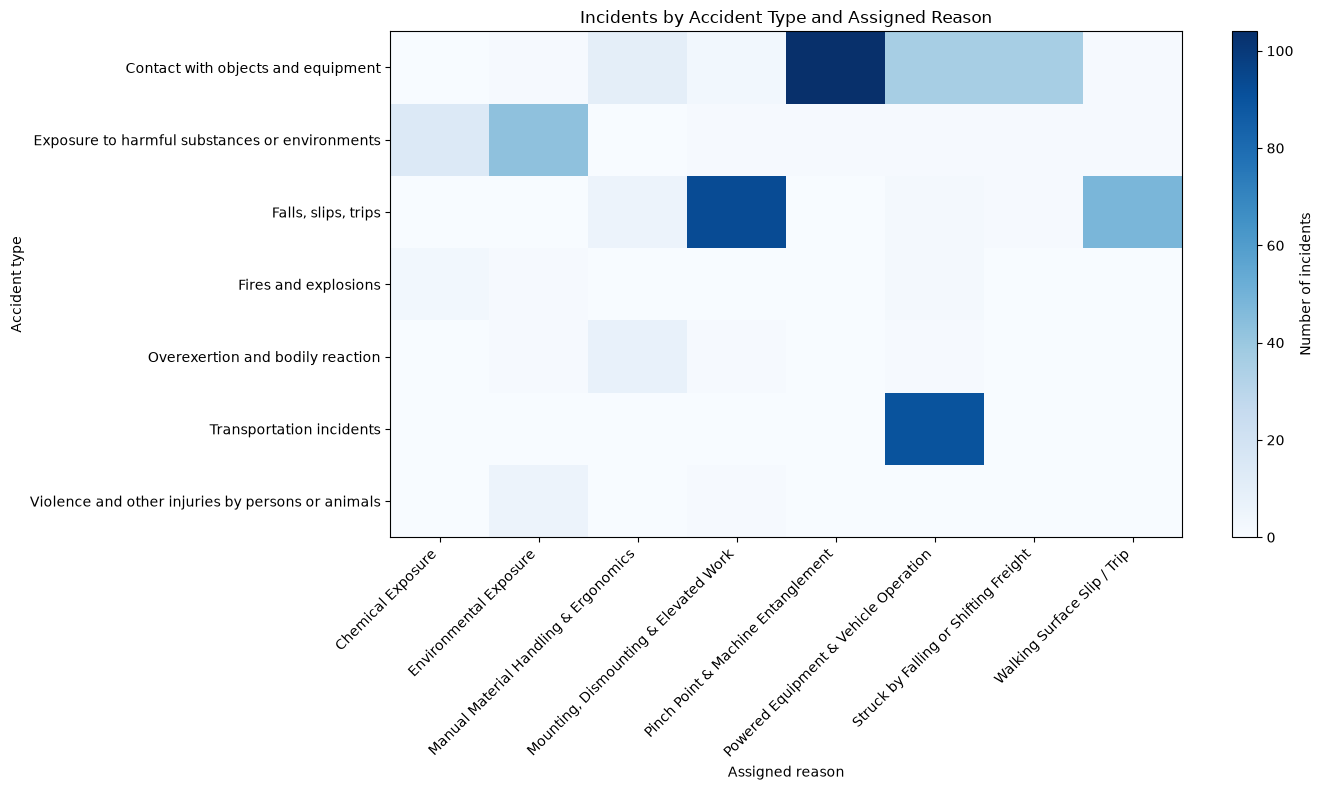

In [16]:
assing = pd.pivot_table(
    data=df,
    index="Types_of_accidents",
    columns="Reason",
    values="ID",
    aggfunc="count",
    fill_value=0
)
assing
print(assing)
plt.figure(figsize=(14, 8))

heatmap = plt.imshow(assing.values, cmap="Blues", aspect="auto")

plt.xticks(
    range(len(assing.columns)),
    assing.columns,
    rotation=45,
    ha="right"
)
plt.yticks(range(len(assing.index)), assing.index)

plt.colorbar(heatmap, label="Number of incidents")
plt.xlabel("Assigned reason")
plt.ylabel("Accident type")
plt.title("Incidents by Accident Type and Assigned Reason")
plt.tight_layout()
plt.show()

# Interpretation: 
Pinch Point & Machine Entanglement was the most frequently assigned reason category for incidents classified as Contact with Objects and Equipment. For Falls, Slips, and Trips, Mounting, Dismounting & Elevated Work appeared most often, followed by Walking Surface Slip/Trip. Powered Equipment & Vehicle Operation appeared most often among Transportation incidents.

4. How many employees were hospitalized in total, and how many incidents involved hospitalization?

In [54]:
total_hospitalized = df['Hospitalized'].sum()
hospitalized_incidents = (df["Hospitalized"] > 0).sum() 

print(f"Total number of hospitalized individuals: {total_hospitalized}")
print()
print(f"Number of incidents with hospitalization: {hospitalized_incidents}")

Total number of hospitalized individuals: 467

Number of incidents with hospitalization: 465


# Interpretation: 
There were 467 hospitalized individuals across 465 incidents involving hospitalization. The difference is because two incidents each involved two hospitalized employees.


5. Which accident types involved the most hospitalized employees?

Types_of_accidents
Falls, slips, trips                                  150
Contact with objects and equipment                   142
Transportation incidents                              88
Exposure to harmful substances or environments        62
Overexertion and bodily reaction                      11
Fires and explosions                                   7
Violence and other injuries by persons or animals      7
Name: Hospitalized, dtype: int64


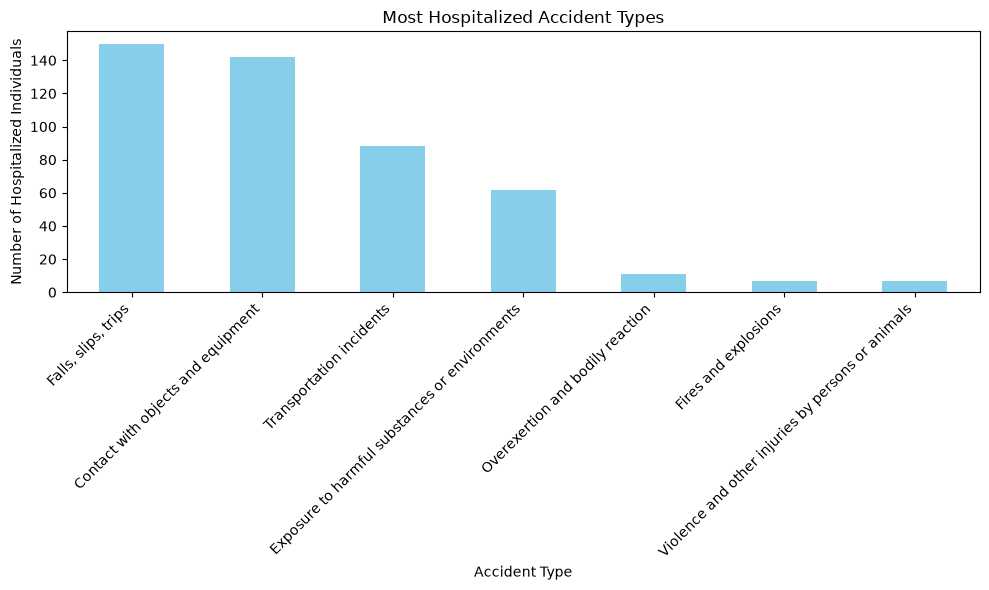

In [17]:
most_hospitalized = df.groupby(['Types_of_accidents'])['Hospitalized'].sum().sort_values(ascending=False)
print(most_hospitalized)

plt.figure(figsize=(10, 6))
most_hospitalized.plot(kind='bar', color='skyblue')
plt.xlabel('Accident Type')
plt.ylabel('Number of Hospitalized Individuals')
plt.title('Most Hospitalized Accident Types')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Interpretation: 
Falls, slips, and trips had the highest number of hospitalized employees, with 150. Contact with objects and equipment ranked second, with 142. Violence and other injuries by persons or animals had the lowest number, with 7.

6. How many incidents involved an amputation, and which accident types were they in?

Total number of amputations: 87

Types_of_accidents
Contact with objects and equipment                   77
Transportation incidents                             10
Exposure to harmful substances or environments        0
Falls, slips, trips                                   0
Fires and explosions                                  0
Overexertion and bodily reaction                      0
Violence and other injuries by persons or animals     0
Name: Amputation, dtype: int64


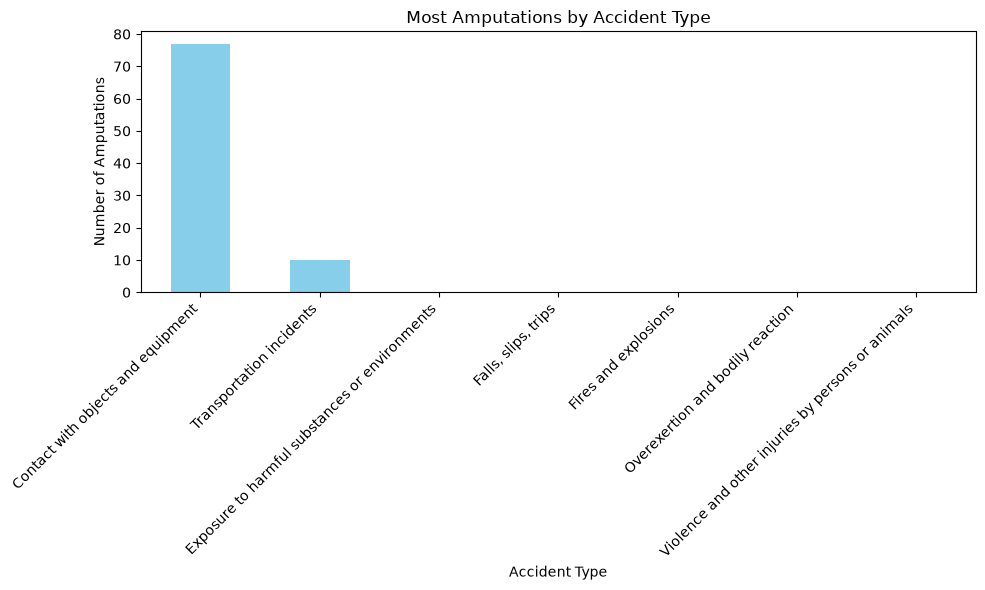

In [53]:

total_amputation_incidents = (df["Amputation"] > 0).sum()

most_amputations =  df.groupby(['Types_of_accidents'])['Amputation'].sum().sort_values(ascending=False)

print(f"Total number of amputations: {total_amputation_incidents.sum()}")
print()

print(most_amputations)

plt.figure(figsize=(10, 6))
most_amputations.plot(kind='bar', color='skyblue')
plt.xlabel('Accident Type')
plt.ylabel('Number of Amputations')
plt.title('Most Amputations by Accident Type')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Interpretation: 
Contact with objects and equipment had the highest number of recorded amputations, with 77. Transportation incidents ranked second, with 10. No amputations were recorded in the other accident-type categories.

7.What share of incidents had an inspection number recorded? Does that vary by accident type?

Number of incidents with inspection recorded: 97

Share of incidents with inspection recorded: 18.76%

Types_of_accidents
Fires and explosions                                 50.00
Exposure to harmful substances or environments       29.03
Violence and other injuries by persons or animals    28.57
Transportation incidents                             24.44
Contact with objects and equipment                   21.47
Falls, slips, trips                                   7.33
Overexertion and bodily reaction                      0.00
Name: Inspection_Recorded, dtype: float64



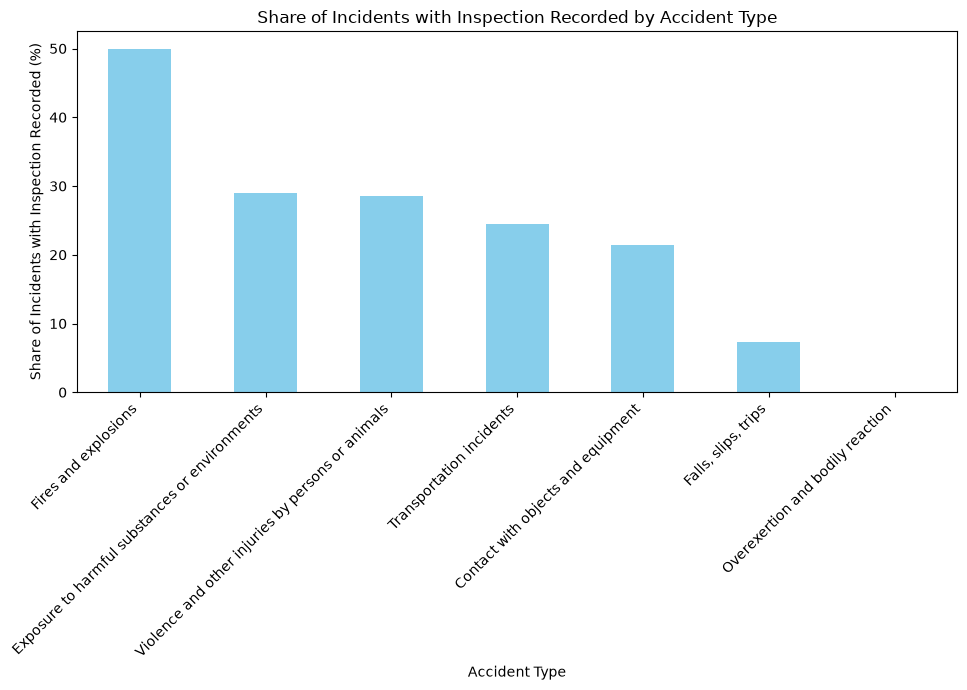

In [48]:
number_of_inspections = df['Inspection_Recorded'].sum()
print(f'Number of incidents with inspection recorded: {number_of_inspections}')
print()
share_of_incidents = (df['Inspection_Recorded'].sum() / len(df)) * 100

print(f"Share of incidents with inspection recorded: {share_of_incidents:.2f}%")
print()

share_of_inspections = df.groupby(['Types_of_accidents'])['Inspection_Recorded'].mean().mul(100).round(2).sort_values(ascending=False)
print(share_of_inspections)
print()

plt.figure(figsize=(10, 7))
share_of_inspections.plot(kind='bar', color='skyblue')
plt.xlabel('Accident Type')
plt.ylabel('Share of Incidents with Inspection Recorded (%)')
plt.title('Share of Incidents with Inspection Recorded by Accident Type')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Interpretation: 
An inspection number was recorded for 97 of the 517 incidents (18.76%). Fires and explosions had the highest inspection-recorded rate, at 50%, followed by exposure to harmful substances or environments, at 29.03%. No inspection number was recorded for incidents classified as overexertion and bodily reaction.

8. How many incidents were reported in each month?

Month_Name
January      46
February     42
March        35
April        38
May          36
June         40
July         50
August       55
September    50
October      55
November     40
December     30
Name: count, dtype: int64


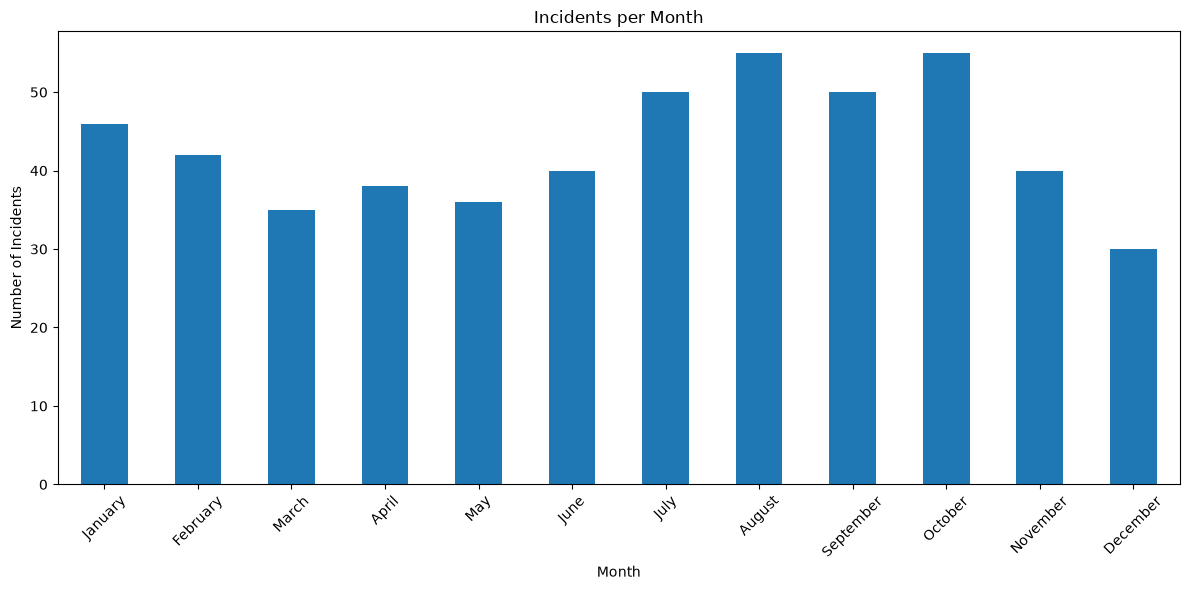

Month_Name  January  February  March  April  May  June  July  August  \
year                                                                   
2015              6         7      3      5    8     8    10       8   
2016              0         0      0      4    2     5     6       9   
2017              7         5      6      0    0     0     0       0   
2019              0         3      3      4    6     8    14       9   
2020              9         7     11      2    6     9     8      11   
2021              8         4      3      7    0     0     0       0   
2023              0         0      0      0    0     0     0       0   
2024              8         7      3      9    6     4     5       6   
2025              8         9      6      7    8     6     7      12   

Month_Name  September  October  November  December  
year                                                
2015                7        9         7         0  
2016                4        3         4        

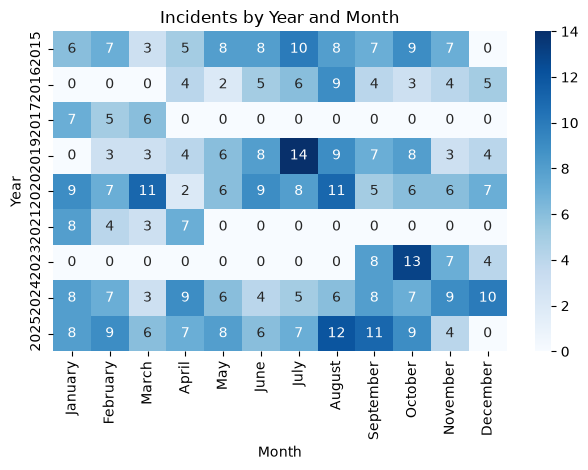

In [9]:
df["EventDate"] = pd.to_datetime(df["EventDate"])

df = df.assign(
    Month=df["EventDate"].dt.month,
    year=df["EventDate"].dt.year
)

month_names = df["Month"].map({
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
})

df["Month_Name"] = month_names

month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]

Incidents_per_Month = (
    df["Month_Name"].value_counts().reindex(month_order, fill_value=0)
)

print(Incidents_per_Month)

plt.figure(figsize=(12, 6))
Incidents_per_Month.plot(kind="bar")
plt.xlabel("Month")
plt.ylabel("Number of Incidents")
plt.title("Incidents per Month")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

yearly_Monthly_Incidents = pd.pivot_table(
    df,
    index="year",
    columns="Month_Name",
    values="ID",
    aggfunc="count",
    fill_value=0
).reindex(columns=month_order, fill_value=0).astype(int)

print(yearly_Monthly_Incidents)

sns.heatmap(yearly_Monthly_Incidents, annot=True, fmt="d", cmap="Blues")
plt.title("Incidents by Year and Month")
plt.xlabel("Month")
plt.ylabel("Year")
plt.tight_layout()
plt.show()

# Interpretation:
From 2015 to 2025, August and October tied for the highest number of reported incidents, with 55 each. July and September had the next-highest counts, while December had the fewest.

The highest monthly number of reported incidents was 14, in July 2019. October 2023 had the next-highest count, with 13 incidents.

9. Which cities had the most reported incidents?

city
HOUSTON          56
DALLAS           40
FORT WORTH       39
SAN ANTONIO      20
ARLINGTON        15
AUSTIN           13
GRAND PRAIRIE    12
LAREDO           12
IRVING           11
EL PASO          10
Name: count, dtype: int64

Number of cities with one incident from 2015 to 2025: 93


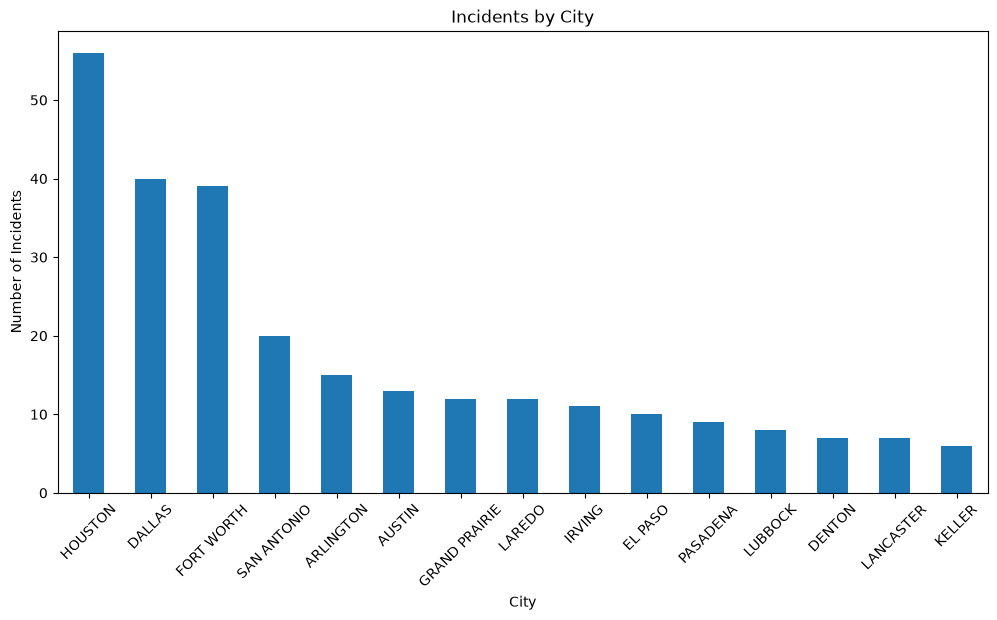

In [55]:
city_counts = df["city"].value_counts()

city_incidents_highest = city_counts.head(10)
city_incidents_lowest = city_counts[city_counts == 1].sum()

print(city_incidents_highest)
print()

print(f'Number of cities with one incident from 2015 to 2025: {city_incidents_lowest}')
plt.figure(figsize=(12, 6))
city_incidents.plot(kind='bar')
plt.xlabel('City')
plt.ylabel('Number of Incidents')
plt.title('Incidents by City')
plt.xticks(rotation=45)
plt.show()

# Interpretation:
From 2015 to 2025, Houston had the highest number of reported incidents, with 56. Dallas ranked second, with 40. In 93 cities, only one incident was reported during this period.

10. How do incident counts and accident types compare across logistics subsectors?

In [11]:
df['Primary_NAICS'].value_counts()

df['Primary_NAICS'] = df['Primary_NAICS'].astype(str)

def logistics(code):
    if code[:3] == '484':
        return 'Truck Transportation'
    if code[:3] == '492':
        return 'Couriers and Messengers'
    else:
        return 'Warehousing and Storage'
df['Logistics_Sector'] = df['Primary_NAICS'].map(logistics)
df[['Primary_NAICS', 'Logistics_Sector']].head(10)

sector_accident_counts = pd.pivot_table(
    data=df,
    index="Logistics_Sector",
    columns="Types_of_accidents",
    values="ID",
    aggfunc="count",
    fill_value=0
)

sector_accident_counts

Types_of_accidents,Contact with objects and equipment,Exposure to harmful substances or environments,"Falls, slips, trips",Fires and explosions,Overexertion and bodily reaction,Transportation incidents,Violence and other injuries by persons or animals
Logistics_Sector,,,,,,,
Couriers and Messengers,23,25,26,0,5,2,4
Truck Transportation,79,27,100,5,3,30,1
Warehousing and Storage,89,10,24,1,3,58,2


Text(120.38563368055553, 0.5, 'Logistics Sector')

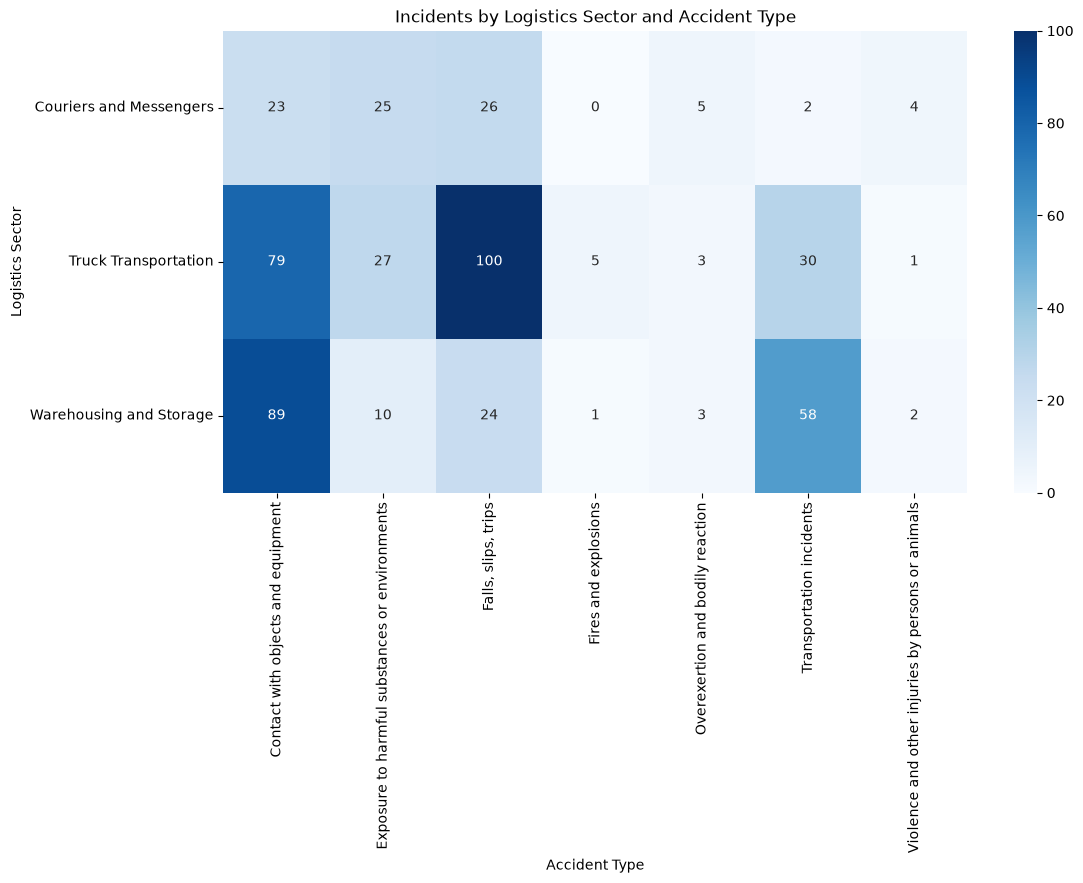

In [14]:
plt.figure(figsize=(12, 6))
sns.heatmap(sector_accident_counts, annot=True, fmt="d", cmap="Blues")
plt.title("Incidents by Logistics Sector and Accident Type")
plt.xlabel("Accident Type")
plt.ylabel("Logistics Sector")

# Interpretation:
Truck Transportation had the highest number of incidents classified as Falls, Slips, and Trips, with 100. For Contact with Objects and Equipment incidents, Warehousing and Storage had the highest count, with 89, followed by Truck Transportation, with 79.